# Airline Operations Analysis

Real BTS reporting-carrier records, 2010–2024. The included fact is a complete aggregation of 180 monthly source files, not a sample.

In [1]:
from pathlib import Path
import pandas as pd,sqlite3
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
f=pd.read_csv(ROOT/'data/fact_airport_month.csv.gz')
print(f'{len(f):,} analytical rows; {int(f.flights.sum()):,} flight records')
print(f.head().to_string(index=False))

253,181 analytical rows; 93,900,879 flight records
 year  month carrier  carrier_id airport  flights  cancelled  diverted  eligible  delayed  severe  unknown  delay_minutes  carrier_minutes  weather_minutes  nas_minutes  security_minutes  late_aircraft_minutes
 2010      1      9E       20363     ABE       65          1         0        64       16       3        0          765.0            440.0              0.0        325.0               0.0                    0.0
 2010      1      9E       20363     AEX       60          4         0        56       17       6        0         1029.0            297.0             99.0        335.0               0.0                  298.0
 2010      1      9E       20363     ALB       81          1         1        79       34       9        0         1535.0            533.0             77.0        700.0               0.0                  225.0
 2010      1      9E       20363     ALO        3          0         0         3        1       0        0   

## Data quality

Missing arrival times are separate from on-time arrivals. Rates use summed numerators and denominators.

In [2]:
assert not f.duplicated(['year','month','carrier_id','airport']).any()
assert len(f[['year','month']].drop_duplicates())==180
assert (f.flights==f[['eligible','cancelled','diverted','unknown']].sum(axis=1)).all()
print('Unique fact grain, 180 reporting months and mutually exclusive outcomes verified.')

Unique fact grain, 180 reporting months and mutually exclusive outcomes verified.


## Annual trends

Reporting coverage expanded in 2018. Traffic trends reflect reporting and carrier composition changes.

 year  flights  delay_rate  cancel_rate  flight_change
 2010  6450117      0.1859       0.0176            NaN
 2011  6085281      0.1864       0.0191        -0.0566
 2012  6096762      0.1690       0.0129         0.0019
 2013  6369482      0.2028       0.0151         0.0447
 2014  5819811      0.2185       0.0218        -0.0863
 2015  5819079      0.1861       0.0154        -0.0001
 2016  5617658      0.1741       0.0117        -0.0346
 2017  5674621      0.1845       0.0146         0.0101
 2018  7206195      0.1912       0.0162         0.2699
 2019  7422037      0.1911       0.0182         0.0300
 2020  4688354      0.0982       0.0599        -0.3683
 2021  5995397      0.1719       0.0172         0.2788
 2022  6729125      0.2108       0.0269         0.1224
 2023  6847899      0.2056       0.0128         0.0177
 2024  7079061      0.2082       0.0136         0.0338


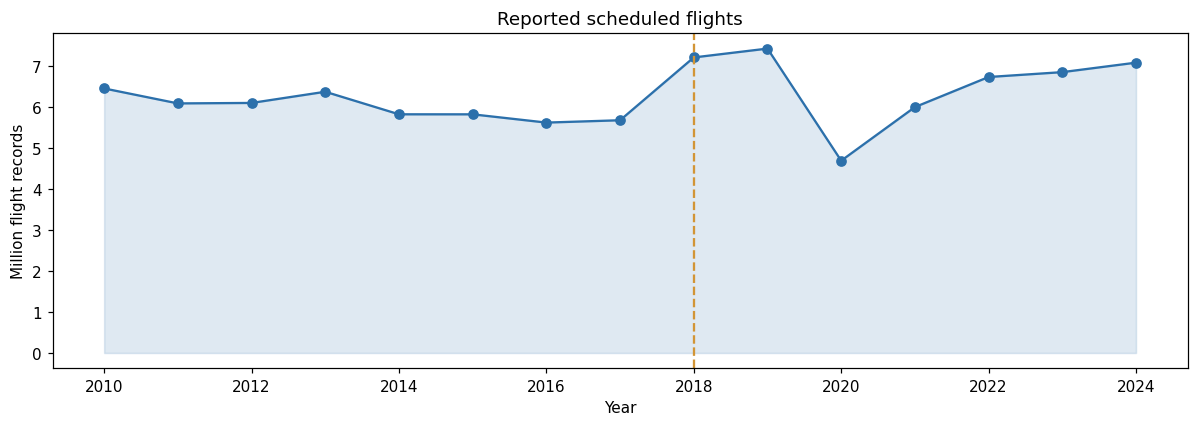

In [3]:
con=sqlite3.connect(':memory:')
f.to_sql('flights',con,index=False)
annual=pd.read_sql_query('SELECT year,SUM(flights) flights,SUM(delayed)*1.0/SUM(eligible) delay_rate,SUM(cancelled)*1.0/SUM(flights) cancel_rate FROM flights GROUP BY year ORDER BY year',con)
annual['flight_change']=annual.flights.pct_change()
print(annual.round(4).to_string(index=False))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(annual.year,annual.flights/1e6,color='#2c70ab',marker='o')
ax.fill_between(annual.year,annual.flights/1e6,color='#2c70ab',alpha=.15)
ax.axvline(2018,color='#d29536',linestyle='--')
ax.set(title='Reported scheduled flights',xlabel='Year',ylabel='Million flight records')
fig.tight_layout()

## Delay-minute contributions

Cause shares describe attributed minutes. Extreme weather is not the full weather impact; NAS includes non-extreme weather.

                           minutes   share
late_aircraft_minutes  427027209.0  0.3949
carrier_minutes        360196043.0  0.3331
nas_minutes            237306401.0  0.2194
weather_minutes         55112552.0  0.0510
security_minutes         1819737.0  0.0017


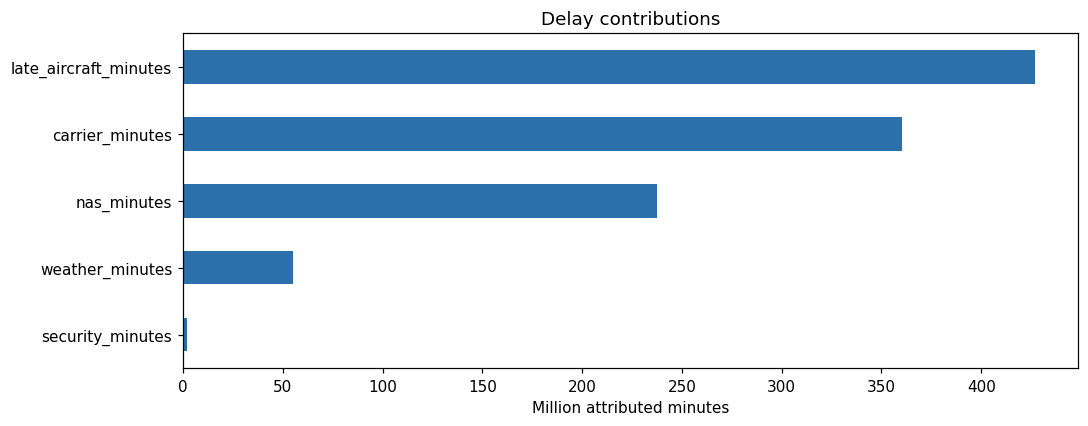

In [4]:
cols=['carrier_minutes','late_aircraft_minutes','nas_minutes','weather_minutes','security_minutes']
c=f[cols].sum().sort_values(ascending=False)
print(pd.DataFrame({'minutes':c,'share':c/c.sum()}).round(4).to_string())
fig,ax=plt.subplots(figsize=(10,4))
(c/1e6).sort_values().plot.barh(ax=ax,color='#2c70ab')
ax.set(xlabel='Million attributed minutes',ylabel='',title='Delay contributions')
fig.tight_layout()

## Matched airport comparison

Both 2019 and 2024 must have at least 100,000 eligible arrivals. This controls airport membership, not traffic mix.

In [5]:
p=f[f.year.isin([2019,2024])].groupby(['airport','year'])[['flights','eligible','delayed']].sum().reset_index()
a=p[p.year.eq(2019)].merge(p[p.year.eq(2024)],on='airport',suffixes=('_2019','_2024'))
a=a[(a.eligible_2019>=100000)&(a.eligible_2024>=100000)]
a['traffic_change']=a.flights_2024/a.flights_2019-1
a['delay_change_pp']=100*(a.delayed_2024/a.eligible_2024-a.delayed_2019/a.eligible_2019)
print(a.sort_values('traffic_change',ascending=False)[['airport','traffic_change','delay_change_pp']].head(15).round(3).to_string(index=False))
con.close()

airport  traffic_change  delay_change_pp
    DEN           0.224           -1.169
    LAS           0.154            3.603
    SEA           0.146            0.104
    MCO           0.115            3.552
    PHX           0.104            1.516
    DFW           0.030            3.741
    DCA           0.004            1.670
    SLC          -0.017            0.954
    JFK          -0.030            1.016
    BOS          -0.047           -1.245
    EWR          -0.052           -8.611
    LGA          -0.054           -7.623
    CLT          -0.076            6.222
    LAX          -0.118            0.596
    ATL          -0.135            3.163


## Findings

- The analysis processes 93,900,879 flight records from 180 monthly source files into 253,181 analytical rows, covering 401 airports and 24 DOT carrier identities.
- 81.2% of eligible arrivals were on time; 18.8% were delayed by at least 15 minutes. Cancellations were 1.9% of scheduled flight records.
- Delayed eligible arrivals averaged 62.6 minutes late. This excludes on-time, cancelled and diverted flights.
- Reported traffic changed by -36.8% in 2020 versus 2019. In 2024, volume was -4.6% relative to 2019; the delay rate changed by +1.7 percentage points.
- Late aircraft accounted for 39.5% of attributed delay minutes, the largest recorded category.
- June had the highest pooled calendar-month delay rate (23.0%); November had the lowest (14.9%).
- Among airports with at least 100,000 eligible arrivals across the full period, EWR had the highest delay rate (25.8%). Rankings are not adjusted for traffic mix.

Prioritise high-volume disruption reviews, investigate the largest recorded delay-minute categories, and validate seasonal planning locally. The analysis is descriptive, not causal.